# a sanity check on an air layer to account for flight height

In [2]:
! pip install torch


[notice] A new release of pip is available: 23.2.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip



  Obtaining dependency information for torch from https://files.pythonhosted.org/packages/37/04/a5cd83baccbf2d4329990ec06b8abf3a644e1559a7b1f764f42d2cb77d51/torch-2.3.0-cp312-cp312-win_amd64.whl.metadata
  Obtaining dependency information for filelock from https://files.pythonhosted.org/packages/41/24/0b023b6537dfc9bae2c779353998e3e99ac7dfff4222fc6126650e93c3f3/filelock-3.14.0-py3-none-any.whl.metadata
  Obtaining dependency information for typing-extensions>=4.8.0 from https://files.pythonhosted.org/packages/e1/4d/d612de852a0bc64a64418e1cef25fe1914c5b1611e34cc271ed7e36174c8/typing_extensions-4.12.0-py3-none-any.whl.metadata
  Obtaining dependency information for sympy from https://files.pythonhosted.org/packages/d2/05/e6600db80270777c4a64238a98d442f0fd07cc8915be2a1c16da7f2b9e74/sympy-1.12-py3-none-any.whl.metadata
  Obtaining dependency information for networkx from https://files.pythonhosted.org/packages/38/e9/5f72929373e1a0e8d142a130f3f97e6ff920070f87f91c4e13e40e0fba5a/networkx-3.3

In [1]:
import torch

from em1d.experiment import Loop, Receiver, Forward
import matplotlib.pyplot as plt
import numpy as np

ModuleNotFoundError: No module named 'torch'

In [ ]:
gpu = torch.device('cuda:0')

In [6]:
lp = Loop.square(6, z=20)
rx = Receiver(z=25)
times = torch.logspace(-5,-2, 31).to(gpu)

\\bubi4.uni.au.dk\people\matt.griffiths\_git\em1d\src\em1d\experiment\experiment.py:264: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times.device)
\\bubi4.uni.au.dk\people\matt.griffiths\_git\em1d\src\em1d\experiment\experiment.py:302: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
\\bubi4.uni.au.dk\people\matt.griffiths\_git\em1d\src\em1d\experiment\experiment.py:303: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather 

10 forwards: 0.4193710999999922


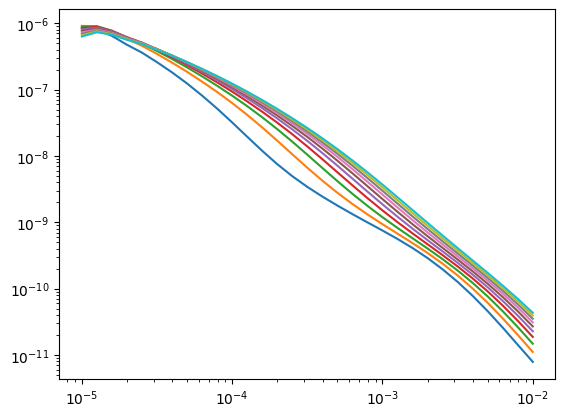

In [7]:

nf = 10
sigma = torch.tensor([0.1, 1, 0.1, 0.3, 10, 25, 0.2, 0.5, 10, 15, 20])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
thick = torch.tensor([40, 40, 40, 40, 40, 40, 40, 40, 40, 40])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]

sigma = sigma.to(gpu)
thick = thick.to(gpu)

fwr = Forward(lp, rx, times)
from time import perf_counter as timer
bt = timer()
dbdt = fwr(sigma, thick)
print(f'{nf} forwards: {timer()-bt}')

# Plot sounding
fig,ax = plt.subplots()
ax.loglog(times.cpu().numpy(), np.abs(dbdt.cpu().numpy().real).T, label='normal_setup')

In [16]:
n_forwards = np.logspace(0, 2.6, 12).astype(int)
t_forwards = np.zeros(n_forwards.shape)

from time import perf_counter as timer

for i_nf,nf in enumerate(n_forwards):
    sigma = torch.tensor([0.1, 1, 0.1, 0.3, 10])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
    thick = torch.tensor([40, 40, 40, 40])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]

    fwr = Forward(lp, rx, times)
    bt = timer()
    for i in range(5):
        dbdt = fwr(sigma, thick)
    t_forwards[i_nf] = (timer()-bt)/5
    del fwr
    print(nf)

1
1
2
5
8
15
26
45
77
134
231


OutOfMemoryError: CUDA out of memory. Tried to allocate 2.58 GiB. GPU 0 has a total capacty of 11.00 GiB of which 0 bytes is free. Of the allocated memory 5.86 GiB is allocated by PyTorch, and 1.64 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting max_split_size_mb to avoid fragmentation.  See documentation for Memory Management and PYTORCH_CUDA_ALLOC_CONF

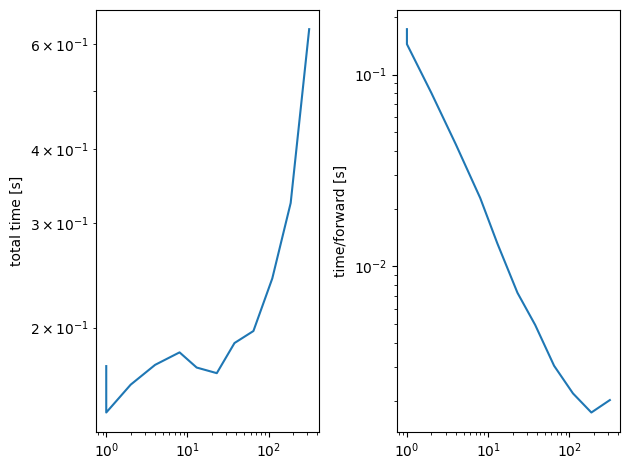

In [15]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(n_forwards, t_forwards);            axs[0].set_ylabel('total time [s]')
axs[1].loglog(n_forwards, t_forwards/n_forwards); axs[1].set_ylabel('time/forward [s]')
# axs[1].set_ylim(0.01, 0.1)
plt.tight_layout()

so appears to be at the machine precision level so that is wonderful.